# 4. Apprentissage semi-supervisé

 La base n'est que partiellement étiquetée : pour chaque propriété mécanique, environ la moitié des soudures n'a pas été mesurée.

 | | Cible A | Cible B |
|---|---|---|
| Variable | `Charpy conforme` (47 J atteints à −20 °C, définie dans le notebook 2) | `Yield strength` (limite d'élasticité) |
| Tâche | Classification binaire | Régression |
| Méthodes (cours CM8) | Self-training · Label spreading (graphe) · CEM semi-supervisé (génératif) | Self-training · Label propagation (graphe) |

**Plan**
1. Données et vérification des hypothèses du semi-supervisé
2. Protocole d'évaluation
3. Méthodes
4. Cible A : Charpy conforme
5. Cible B : limite d'élasticité
6. Synthèse et discussion

## Rappel : les trois familles de méthodes

On dispose de $m$ exemples étiquetés $S = \{(x_i, y_i)\}_{i=1}^{m}$ et de $u$ exemples non étiquetés $U = \{x_i\}_{i=m+1}^{m+u}$. On veut une fonction $h : x \mapsto y$ meilleure que celle apprise sur $S$ seul, en exploitant la structure de $U$.

| Famille | Principe | Hypothèse utilisée | Ici |
|---|---|---|---|
| **Générative** (CEM semi-supervisé) | Les données sont un mélange de lois, une par classe. Étape E : probabilité d'appartenance de chaque $x \in U$ ; étape C : affectation à la classe la plus probable ; étape M : ré-estimation des paramètres sur $S \cup U$ | Lissité | Cible A |
| **Discriminante** (self-training) | Un modèle supervisé prédit $U$ ; les prédictions les plus **sûres** deviennent des pseudo-étiquettes ; on ré-entraîne ; on itère. C'est « la version discriminante de CEM » | Séparation en zone de faible densité | Cibles A et B |
| **Graphe** (label propagation / spreading) | Graphe des $k$ plus proches voisins sur $S \cup U$ ; les étiquettes « diffusent » vers les voisins en minimisant $\lVert S\tilde Y - SY\rVert^2 + \lambda\,\tilde Y^\top (D - W)\tilde Y$, de solution $\tilde Y^* = (S + \lambda(D - W))^{-1} S Y$ | Lissité / variété | Cibles A et B |

**Ces méthodes ne marchent que si leurs hypothèses sont vérifiées** : il faut que les soudures non étiquetées « ressemblent » aux étiquetées (même zone de l'espace des entrées). On le vérifie en section 1.

## 0. Imports et paramètres

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.sparse.linalg import spsolve

from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score,
                             mean_absolute_error, r2_score, root_mean_squared_error)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors, kneighbors_graph
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.semi_supervised import LabelSpreading, SelfTrainingClassifier

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
# LabelSpreading émet un RuntimeWarning pour les soudures sans aucun voisin étiqueté : géré par SafeLabelSpreading (section 3.4)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn.semi_supervised")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42          # même graine que le notebook 3
N_FOLDS = 5                # même nombre de plis que le notebook 3
N_TREES = 200              # nombre d'arbres des forêts (baisser à 100 si c'est trop long)
FRACTIONS = [0.1, 0.25, 0.5, 1.0]   # part des étiquettes d'entraînement conservées (courbe d'apprentissage)

PATH_INTER = Path("..") / "1. Données" / "02_intermediate"
PATH_FIG = Path("..") / "3. Résultats" / "figures"
PATH_FIG.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(PATH_FIG / f"ssl_{name}.png", dpi=150, bbox_inches="tight")

## 1. Données

On part du même fichier que le notebook 3 (`welddb_processed_vf.csv`, produit par le notebook 2), avec les mêmes choix :
- `Charpy impact toughness` et `Charpy temperature` sont retirées des entrées : elles servent à **construire** la cible `Charpy conforme` (les garder donnerait la réponse au modèle) ;
- toutes les cibles sont retirées des entrées (une cible ne doit pas servir à en prédire une autre : pour une nouvelle soudure, on ne les connaît pas) ;
- `Weld ID` (la publication d'origine) sert uniquement à grouper les plis.

In [2]:
df = pd.read_csv(PATH_INTER / "welddb_processed_vf.csv", sep=";")
corresp = pd.read_csv(PATH_INTER / "correspondance_between_names_units_vf.csv", sep=";")

ID_COL = "Weld ID"
TARGETS = [t for t in corresp.loc[corresp["Role"] == "Quality indicator", "Feature"] if t in df.columns]
DROP = TARGETS + [ID_COL, "Charpy impact toughness", "Charpy temperature"]

X_all = df.drop(columns=[c for c in DROP if c in df.columns])
groups_all = df[ID_COL]

COL_NUM = [c for c in X_all.columns if pd.api.types.is_numeric_dtype(X_all[c])]
COL_CAT = [c for c in X_all.columns if c not in COL_NUM]

print(f"{X_all.shape[1]} entrées ({len(COL_NUM)} numériques, {len(COL_CAT)} catégorielles : {COL_CAT})")
print(f"Cibles retirées des entrées : {TARGETS}")

TARGET_A, TARGET_B = "Charpy conforme", "Yield strength"
for t in (TARGET_A, TARGET_B):
    lab = df[t].notna()
    print(f"\n{t} : {lab.sum()} étiquetées, {(~lab).sum()} non étiquetées")
print("\nRépartition Charpy conforme :", df[TARGET_A].value_counts().to_dict())

25 entrées (22 numériques, 3 catégorielles : ['AC or DC', 'Electrode positive or negative', 'Type of weld'])
Cibles retirées des entrées : ['Yield strength', 'Ultimate tensile strength', 'Elongation', 'Reduction of Area', 'Charpy impact toughness', 'Charpy conforme']

Charpy conforme : 481 étiquetées, 1171 non étiquetées

Yield strength : 780 étiquetées, 872 non étiquetées

Répartition Charpy conforme : {1.0: 437, 0.0: 44}


### 1.1 Justification du semi-supervisé

Le semi-supervisé repose sur l'hypothèse de **lissité** : deux soudures proches dans l'espace des entrées ont des propriétés proches. Pour que les non-étiquetées aident, il faut qu'elles soient **dans la même zone** que les étiquetées : si elles décrivent d'autres familles d'aciers, elles n'apportent rien (voire induisent le modèle en erreur).

Deux vérifications :
1. **par la source** : quelle part des soudures non étiquetées vient d'une publication qui contient aussi des soudures étiquetées ?
2. **par l'ACP** : les nuages étiquetés / non étiquetés se superposent-ils ?

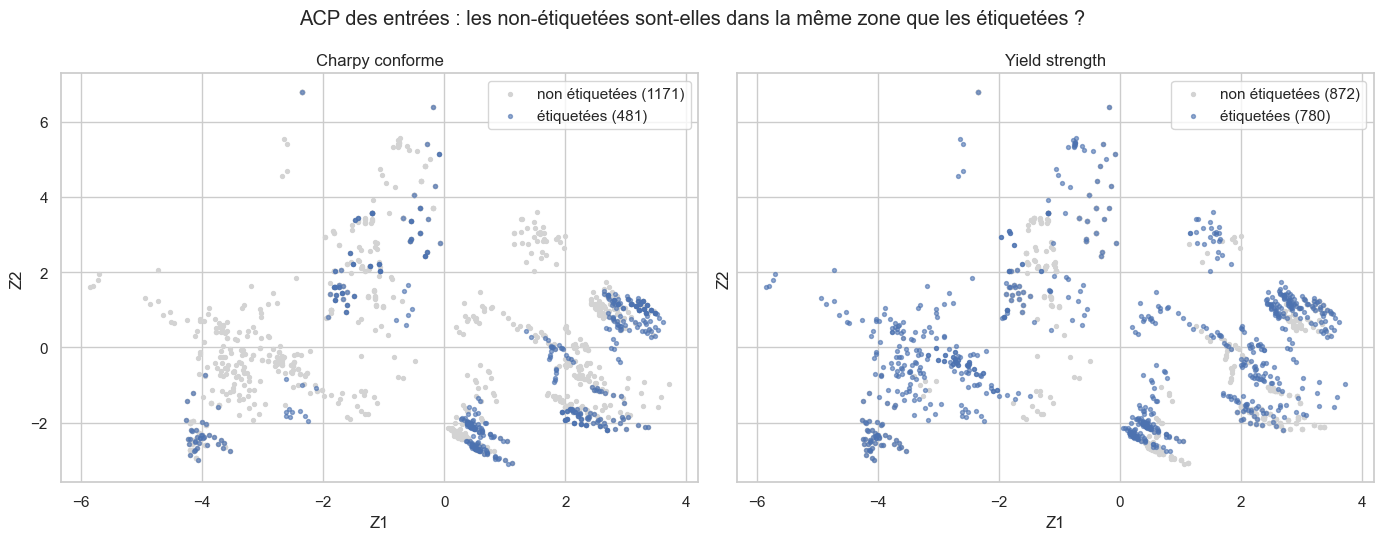

Charpy conforme    : 64% des soudures non étiquetées viennent d'une publication qui a aussi des soudures étiquetées
Yield strength     : 81% des soudures non étiquetées viennent d'une publication qui a aussi des soudures étiquetées


In [3]:
def make_prep():
    '''Imputation (moyenne, choix du notebook 3) + standardisation + one-hot.
    La standardisation est indispensable ici : label spreading et CEM reposent sur des distances.'''
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="mean", add_indicator=True), StandardScaler()), COL_NUM),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), COL_CAT),
    ])

Z_all = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(make_prep().fit_transform(X_all))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
overlap = {}
for ax, t in zip(axes, (TARGET_A, TARGET_B)):
    lab = df[t].notna().values
    ax.scatter(Z_all[~lab, 0], Z_all[~lab, 1], s=8, c="lightgrey", label=f"non étiquetées ({(~lab).sum()})")
    ax.scatter(Z_all[lab, 0], Z_all[lab, 1], s=8, c="C0", alpha=.6, label=f"étiquetées ({lab.sum()})")
    ax.set_title(t); ax.set_xlabel("Z1"); ax.set_ylabel("Z2"); ax.legend(loc="upper right")
    sources_lab = set(groups_all[lab])
    overlap[t] = groups_all[~lab].isin(sources_lab).mean()
plt.suptitle("ACP des entrées : les non-étiquetées sont-elles dans la même zone que les étiquetées ?")
plt.tight_layout(); savefig("acp_etiquetees"); plt.show()

for t, v in overlap.items():
    print(f"{t:18s} : {v:.0%} des soudures non étiquetées viennent d'une publication qui a aussi des soudures étiquetées")

Les nuages se superposent largement et une grande part des non-étiquetées vient de publications communes, l'hypothèse de lissité est donc **plausible** et le semi-supervisé a une chance d'aider. Les zones où il n'y a que des points gris sont des familles d'aciers jamais étiquetées : aucune méthode ne pourra y propager d'information fiable.

## 2. Protocole d'évaluation

Le point le plus important : **on évalue toujours sur de vraies étiquettes, jamais sur des pseudo-étiquettes**, et on compare chaque méthode semi-supervisée au **même type de modèle entraîné en supervisé seul**.

Pour chaque pli de la validation croisée :

| Ensemble | Contenu | Utilisation |
|---|---|---|
| **Test** | soudures étiquetées des publications du pli de test | évaluation uniquement |
| **Train étiqueté $S$** | soudures étiquetées des autres publications | entraînement (supervisé et semi-supervisé) |
| **Train non étiqueté $U$** | soudures **sans** étiquette, **hors publications du test** | entraînement semi-supervisé uniquement, **sans leur étiquette** |

Choix et justifications :
- **`StratifiedGroupKFold` par publication**, mêmes paramètres que le notebook 3 (5 plis, `random_state=42`) : une publication est entièrement d'un seul côté, sinon le modèle reconnaît la « signature » d'une étude et le score est trop optimiste ;
- **les non-étiquetées des publications du test sont exclues de $U$** : même sans étiquette, leurs entrées décrivent les soudures du test, et le graphe ou le self-training pourraient s'en servir pour « préparer » le test. On se place ainsi dans le cas réaliste d'une soudure provenant d'une étude jamais vue ;
- **le préprocessing (imputation, standardisation) est appris sur $S \cup U$** pour toutes les méthodes, y compris supervisées : utiliser les entrées non étiquetées pour l'imputation est déjà légitime (elles sont disponibles), et ça permet d'isoler l'effet de l'**algorithme** semi-supervisé ;
- **métriques calculées sur les prédictions regroupées des 5 plis** (*pooled*) plutôt que moyennées pli par pli : les 44 soudures non conformes viennent de seulement 8 publications, si bien qu'un pli de test peut n'en contenir **aucune** (la balanced accuracy de ce pli n'a alors pas de sens). Regrouper les prédictions hors-pli est la pratique recommandée dans ce cas (Forman & Scholz, 2010). L'incertitude est estimée par **bootstrap sur les publications** (on tire des publications entières avec remise, car les soudures d'une même publication ne sont pas indépendantes — même démarche que le notebook 3) ;
- **courbe d'apprentissage** : on ne garde qu'une fraction (10 %, 25 %, 50 %, 100 %) des étiquettes de $S$, les autres sont **cachées** et rejoignent $U$. Le semi-supervisé est censé aider surtout quand les étiquettes sont rares ; cette courbe montre jusqu'où.

In [4]:
def make_folds(y, groups, task):
    '''Mêmes plis que le notebook 3 : stratifiés (classes, ou quintiles de y en régression) et groupés par publication.'''
    strata = y.astype(int) if task == "classification" else pd.qcut(y, q=5, labels=False)
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    return list(sgkf.split(np.zeros(len(y)), strata, groups))


def subsample_labels(y_train, frac, task, rng):
    '''Garde une fraction des étiquettes du train (stratifiée en classification, au moins 3 par classe).'''
    idx = np.arange(len(y_train))
    if frac >= 1:
        return idx
    if task == "classification":
        keep = []
        for c in np.unique(y_train):
            idc = idx[y_train == c]
            keep.append(rng.choice(idc, size=max(3, int(round(frac * len(idc)))), replace=False))
        return np.sort(np.concatenate(keep))
    return np.sort(rng.choice(idx, size=max(10, int(round(frac * len(idx)))), replace=False))

## 3. Méthodes

| Méthode | Famille (CM8) | Équivalent supervisé de référence | Implémentation |
|---|---|---|---|
| Self-training | Discriminante | Random Forest | `SelfTrainingClassifier` (scikit-learn) ; `SelfTrainingRegressor` (codé ci-dessous) |
| Label spreading / propagation | Graphe | k plus proches voisins (kNN) | `LabelSpreading` (scikit-learn) ; `GraphPropagationRegressor` (codé ci-dessous, formule du cours) |
| CEM semi-supervisé | Générative | Mélange gaussien appris sur $S$ seul | `SemiSupervisedCEM` (codé ci-dessous, algorithme du cours) |

Chaque méthode semi-supervisée est comparée à **son** équivalent supervisé : c'est ce qui permet d'attribuer un éventuel gain aux données non étiquetées et non au changement de modèle.

### 3.1 Self-training en régression

`SelfTrainingClassifier` n'existe qu'en classification, car il mesure la confiance par une probabilité de classe. En régression, on mesure la confiance par le **désaccord entre les arbres** de la forêt : chaque arbre est entraîné sur un échantillon bootstrap différent ; si leurs prédictions pour une soudure sont proches (écart-type faible), la prédiction est jugée fiable.

À chaque itération, on ajoute aux données d'entraînement les `frac_per_iter` (20 %) des soudures non étiquetées les plus sûres, avec leur prédiction comme pseudo-étiquette.

> Limite connue (*biais de confirmation*) : des arbres d'accord ne sont pas forcément justes, surtout loin des données d'entraînement ; une erreur pseudo-étiquetée est ensuite apprise comme une vérité. C'est pourquoi on n'ajoute que les prédictions les plus sûres et on limite le nombre d'itérations.

In [5]:
class SelfTrainingRegressor(BaseEstimator, RegressorMixin):
    '''Self-training pour la régression. y = NaN pour les exemples non étiquetés.
    La confiance d'une prédiction = écart-type des prédictions des arbres (estimateur de type forêt).'''

    def __init__(self, estimator, frac_per_iter=0.2, max_iter=5):
        self.estimator = estimator
        self.frac_per_iter = frac_per_iter
        self.max_iter = max_iter

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y, dtype=float)
        lab = ~np.isnan(y)
        X_l, y_l, X_u = X[lab], y[lab], X[~lab]
        n_add = max(1, int(self.frac_per_iter * len(X_u)))
        self.n_pseudo_labels_ = 0
        for _ in range(self.max_iter):
            if len(X_u) == 0:
                break
            model = clone(self.estimator).fit(X_l, y_l)
            per_tree = np.stack([tree.predict(X_u) for tree in model.estimators_])
            mean, std = per_tree.mean(axis=0), per_tree.std(axis=0)
            sure = np.argsort(std)[:n_add]                    # les plus sûres = arbres les plus d'accord
            X_l = np.vstack([X_l, X_u[sure]])
            y_l = np.concatenate([y_l, mean[sure]])
            X_u = np.delete(X_u, sure, axis=0)
            self.n_pseudo_labels_ += len(sure)
        self.estimator_ = clone(self.estimator).fit(X_l, y_l)
        return self

    def predict(self, X):
        return self.estimator_.predict(np.asarray(X))

### 3.2 Propagation sur graphe en régression

`LabelSpreading` de scikit-learn ne fait que de la classification. Or la formule du cours s'applique telle quelle à des étiquettes **réelles** :

$$\tilde Y^* = \big(S + \lambda (D - W)\big)^{-1} S\,Y$$

- $W$ : graphe des $k$ plus proches voisins sur $S \cup U$ (matrice binaire symétrisée, $w_{ii} = 0$) ; $D$ : matrice diagonale des degrés ; $D - W$ est le **laplacien** du graphe ;
- $S$ : matrice diagonale valant 1 pour les exemples étiquetés, 0 sinon ;
- $\lambda$ règle le compromis entre fidélité aux vraies étiquettes et lissité sur le graphe.

Deux ajouts techniques : on **centre** $y$ (une soudure isolée de toute étiquette reçoit la moyenne plutôt que 0), et on ajoute $\varepsilon I$ pour que la matrice soit toujours inversible.
Pour prédire une **nouvelle** soudure (qui n'est pas dans le graphe), on moyenne les valeurs propagées de ses $k$ plus proches voisins du graphe, pondérées par l'inverse de la distance.

In [6]:
class GraphPropagationRegressor(BaseEstimator, RegressorMixin):
    '''Propagation d'étiquettes réelles sur un graphe kNN : Y* = (S + lambda (D - W))^-1 S Y. y = NaN si non étiqueté.'''

    def __init__(self, n_neighbors=10, lam=0.5, eps=1e-6):
        self.n_neighbors = n_neighbors
        self.lam = lam
        self.eps = eps

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y, dtype=float)
        lab = ~np.isnan(y)
        self.mean_ = y[lab].mean()
        W = kneighbors_graph(X, self.n_neighbors, mode="connectivity", include_self=False)
        W = W.maximum(W.T)                                         # graphe symétrique
        L = sparse.diags(np.asarray(W.sum(axis=1)).ravel()) - W    # laplacien D - W
        S = sparse.diags(lab.astype(float))
        rhs = S @ np.where(lab, y - self.mean_, 0.0)
        A = (S + self.lam * L + self.eps * sparse.identity(len(y))).tocsc()
        self.y_graph_ = self.mean_ + spsolve(A, rhs)
        self.nn_ = NearestNeighbors(n_neighbors=self.n_neighbors).fit(X)
        return self

    def predict(self, X):
        dist, idx = self.nn_.kneighbors(np.asarray(X))
        w = 1.0 / (dist + 1e-9)
        return (w * self.y_graph_[idx]).sum(axis=1) / w.sum(axis=1)

### 3.3 CEM semi-supervisé

Chaque classe $k$ est modélisée par une loi gaussienne $\mathcal N(\mu_k, \Sigma_k)$ de proportion $\pi_k$. Algorithme du cours :
1. **initialisation** : $\pi_k, \mu_k, \Sigma_k$ estimés sur les exemples étiquetés ;
2. **étape E** : probabilité a posteriori de chaque classe pour chaque $x \in U$ : $\;\pi_k\,\mathcal N(x \mid \mu_k, \Sigma_k) / \sum_l \pi_l\,\mathcal N(x \mid \mu_l, \Sigma_l)$ ;
3. **étape C** : chaque $x \in U$ est affecté à la classe la plus probable ;
4. **étape M** : ré-estimation de $\pi_k, \mu_k, \Sigma_k$ sur $S \cup U$ (étiquettes vraies + affectations) ;
5. on répète jusqu'à ce que les affectations ne changent plus.

Choix pratiques :
- les gaussiennes sont estimées dans l'espace des **10 premières composantes de l'ACP** (apprise sur $S \cup U$, hypothèse de **variété** du cours) : avec ~40 entrées et peu de soudures non conformes, une covariance complète en dimension 40 serait impossible à estimer ;
- covariances **diagonales** (`covariance_type="diag"`) pour la même raison ;
- avec `max_iter=0`, on obtient exactement le **même modèle appris sur $S$ seul** : c'est la référence supervisée.

In [7]:
class SemiSupervisedCEM(BaseEstimator, ClassifierMixin):
    '''CEM semi-supervisé (Celeux & Govaert 1991 ; cours CM8). y = -1 pour les exemples non étiquetés.
    max_iter=0 -> modèle gaussien appris sur les étiquetés seuls (référence supervisée).'''

    def __init__(self, max_iter=50, covariance_type="diag", reg=1e-3):
        self.max_iter = max_iter
        self.covariance_type = covariance_type
        self.reg = reg

    def _m_step(self, X, y):
        self.priors_, self.means_, self.covs_ = [], [], []
        for k in self.classes_:
            Xk = X[y == k]
            self.priors_.append(len(Xk) / len(X))
            self.means_.append(Xk.mean(axis=0))
            var = Xk.var(axis=0) + self.reg if len(Xk) > 1 else np.ones(X.shape[1])
            cov = np.diag(var) if self.covariance_type == "diag" else np.cov(Xk.T) + self.reg * np.eye(X.shape[1])
            self.covs_.append(cov)

    def _log_joint(self, X):
        out = []
        for p, m, c in zip(self.priors_, self.means_, self.covs_):
            diff = X - m
            _, logdet = np.linalg.slogdet(c)
            maha = np.einsum("ij,jk,ik->i", diff, np.linalg.inv(c), diff)
            out.append(np.log(p) - 0.5 * (logdet + maha + X.shape[1] * np.log(2 * np.pi)))
        return np.column_stack(out)

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        lab = y != -1
        self.classes_ = np.unique(y[lab])
        self._m_step(X[lab], y[lab])                               # initialisation sur S
        y_u = None
        self.n_iter_ = 0
        for it in range(self.max_iter):
            if lab.all():
                break
            post = self._log_joint(X[~lab])                        # étape E (log-probabilités jointes)
            new_y_u = self.classes_[post.argmax(axis=1)]           # étape C
            if y_u is not None and np.array_equal(new_y_u, y_u):
                break
            y_u = new_y_u
            y_full = y.copy()
            y_full[~lab] = y_u                                     # vraies étiquettes sur S, affectations sur U
            self._m_step(X, y_full)                                # étape M sur S ∪ U
            self.n_iter_ = it + 1
        return self

    def predict_proba(self, X):
        lj = self._log_joint(np.asarray(X, dtype=float))
        lj -= lj.max(axis=1, keepdims=True)
        p = np.exp(lj)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

### 3.4 Label spreading : cas des soudures isolées

`LabelSpreading` prédit une nouvelle soudure à partir des valeurs propagées sur ses voisins du graphe. Si aucun de ces voisins n'a reçu d'information (composante du graphe sans aucune soudure étiquetée), la probabilité vaut 0/0 = `NaN`, et `predict` renverrait alors arbitrairement la première classe (« non conforme »), ce qui fausserait les scores. Dans ce cas, on prédit la **proportion des classes** observée sur les étiquetées (le modèle « ne sait pas »).

In [8]:
class SafeLabelSpreading(LabelSpreading):
    '''LabelSpreading dont les probabilités indéfinies (soudures isolées) sont remplacées par la proportion des classes.'''

    def fit(self, X, y):
        super().fit(X, y)
        y = np.asarray(y)
        self.prior_ = np.array([(y[y != -1] == c).mean() for c in self.classes_])
        return self

    def predict_proba(self, X):
        p = super().predict_proba(X)
        bad = ~np.isfinite(p).all(axis=1) | (p.sum(axis=1) == 0)
        p[bad] = self.prior_
        self.n_isolated_ = int(bad.sum())
        return p

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

### 3.5 Boucle d'évaluation commune

In [ ]:
def classification_scores(y_true, y_pred):
    return {"balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "F1 non conforme": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
            "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0)}

def regression_scores(y_true, y_pred):
    return {"RMSE": root_mean_squared_error(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred)}


def run_experiment(target, task, methods, fractions=FRACTIONS):
    '''Pour chaque pli et chaque fraction d'étiquettes : entraîne toutes les méthodes, évalue sur le test (vraies étiquettes).
    methods = {nom: (modèle, utilise_les_non_etiquetees)}'''
    y_full = df[target]
    lab_mask = y_full.notna().values
    X_lab, y_lab, g_lab = X_all[lab_mask].reset_index(drop=True), y_full[lab_mask].reset_index(drop=True), groups_all[lab_mask].reset_index(drop=True)
    X_unl_all, g_unl_all = X_all[~lab_mask].reset_index(drop=True), groups_all[~lab_mask].reset_index(drop=True)
    if task == "classification":
        y_lab = y_lab.astype(int)
    missing = -1 if task == "classification" else np.nan

    preds = []
    for fold, (tr, te) in enumerate(make_folds(y_lab, g_lab, task)):
        test_sources = set(g_lab.iloc[te])
        X_unl = X_unl_all[~g_unl_all.isin(test_sources).values]       # U sans les publications du test
        X_tr, y_tr, X_te, y_te = X_lab.iloc[tr], y_lab.iloc[tr].values, X_lab.iloc[te], y_lab.iloc[te].values

        for frac in fractions:
            rng = np.random.default_rng(RANDOM_STATE + fold)
            keep = subsample_labels(y_tr, frac, task, rng)
            hidden = np.setdiff1d(np.arange(len(y_tr)), keep)
            X_S, y_S = X_tr.iloc[keep], y_tr[keep]
            X_U = pd.concat([X_unl, X_tr.iloc[hidden]])                # étiquettes cachées -> rejoignent U

            prep = make_prep().fit(pd.concat([X_S, X_U]))
            Z_S, Z_U, Z_te = prep.transform(X_S), prep.transform(X_U), prep.transform(X_te)
            Z_SU = np.vstack([Z_S, Z_U])
            y_SU = np.concatenate([y_S, np.full(len(Z_U), missing)])

            for name, (model, semi) in methods.items():
                m = clone(model)
                m.fit(Z_SU, y_SU) if semi else m.fit(Z_S, y_S)
                preds.append(pd.DataFrame({"fold": fold, "fraction": frac, "méthode": name, "semi": semi,
                                           "groupe": g_lab.iloc[te].values, "y": y_te, "y_hat": m.predict(Z_te),
                                           "n_S": len(y_S), "n_U": len(Z_U)}))
        print(f"pli {fold + 1}/{N_FOLDS} terminé")
    return pd.concat(preds, ignore_index=True)


def pooled_scores(preds, scorer):
    '''Métriques calculées sur les prédictions hors-pli regroupées, pour chaque (méthode, fraction).'''
    rows = [{"méthode": m, "fraction": f, **scorer(p["y"], p["y_hat"])}
            for (m, f), p in preds.groupby(["méthode", "fraction"], sort=False)]
    return pd.DataFrame(rows)


def bootstrap_ci(preds, scorer, metric, n_boot=500, frac=1.0):
    '''Intervalle à 95 % par bootstrap sur les publications (tirage de publications entières avec remise).'''
    rng = np.random.default_rng(RANDOM_STATE)
    out = {}
    for m, p in preds[preds["fraction"] == frac].groupby("méthode", sort=False):
        by_group = {g: d for g, d in p.groupby("groupe")}
        names = list(by_group)
        vals = []
        for _ in range(n_boot):
            sample = pd.concat([by_group[g] for g in rng.choice(names, size=len(names), replace=True)])
            vals.append(scorer(sample["y"], sample["y_hat"])[metric])
        out[m] = np.percentile(vals, [2.5, 97.5])
    return out


def summary(preds, scorer, metrics, ci_metric):
    '''Synthèse à 100 % des étiquettes : métriques sur les prédictions regroupées + IC 95 % sur la métrique principale.'''
    tab = pooled_scores(preds[preds["fraction"] == 1.0], scorer).set_index("méthode")[metrics]
    ci = bootstrap_ci(preds, scorer, ci_metric)
    tab[f"{ci_metric} IC 95 %"] = [f"[{ci[m][0]:.3g} ; {ci[m][1]:.3g}]" for m in tab.index]
    return tab.round(3)


def plot_learning_curve(preds, scorer, metric, title, name, pairs):
    '''pairs = [(méthode supervisée, méthode semi-supervisée, couleur)] : même couleur, trait plein = semi-supervisé.'''
    agg = pooled_scores(preds, scorer)
    fig, ax = plt.subplots(figsize=(8, 5))
    for sup, semi, color in pairs:
        for meth, ls, mk in ((sup, "--", "o"), (semi, "-", "s")):
            a = agg[agg["méthode"] == meth].sort_values("fraction")
            ax.plot(a["fraction"] * 100, a[metric], ls=ls, marker=mk, color=color, label=meth)
    ax.set_xscale("log"); ax.set_xticks([f * 100 for f in FRACTIONS]); ax.set_xticklabels([f"{int(f*100)} %" for f in FRACTIONS])
    ax.set_xlabel("Part des étiquettes d'entraînement conservées"); ax.set_ylabel(metric)
    ax.set_title(title); ax.legend(fontsize=8, ncol=2)
    plt.tight_layout(); savefig(name); plt.show()